# Evaluation of a diffusion model for ECG generation

The diffusion model was trained during 977 epochs with 80 % of the training data from "ECG Heartbeat Categorization Dataset" at Kaggle.

The goal of this notebook is to evaluate the model on data not use during training to see if the the model is capable of generating credible ECG.


In [7]:
import torch
import pandas as pd
import numpy as np
import random
from scipy.stats import norm
from denoisingSeqAutoEncoder import AEncoder1DUNet
import fdasrsf as fs
import dtw
from tqdm import tqdm

In [8]:
df = pd.read_csv("mitbih_train.csv", header=None)

random_seed = 42

torch.manual_seed(random_seed)
random.seed(random_seed)

nb_step = 100
linear_Beta = np.linspace(1e-6, 2e-1, nb_step)
alpha = np.cumprod(1 - linear_Beta, dtype=np.float32)

if torch.xpu.is_available():
    device = torch.device("xpu")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")


### Loading the model
The model's architecture is a 1D UNet.

In [9]:
real_ecg_signal = df.to_numpy()
real_ecg_signal = (real_ecg_signal - np.min(real_ecg_signal))/(np.max(real_ecg_signal) - np.min(real_ecg_signal))
model = AEncoder1DUNet()
model.load_state_dict(torch.load("ddpm_model.pt", weights_only=True))
model.to(device=device)
model.eval()

AEncoder1DUNet(
  (encode_block_1): CNNEncoderBlock(
    (l1_conv): Conv1d(1, 1, kernel_size=(5,), stride=(1,), padding=(2,))
    (l2_conv): Conv1d(1, 1, kernel_size=(5,), stride=(1,), padding=(2,))
    (l3_conv): Conv1d(1, 1, kernel_size=(5,), stride=(1,), padding=(2,))
    (l4_conv): Conv1d(1, 1, kernel_size=(5,), stride=(1,), padding=(2,))
    (l1_act): ReLU()
    (l2_act): ReLU()
    (l3_act): ReLU()
    (l4_act): ReLU()
  )
  (encode_block_2): CNNEncoderBlock(
    (l1_conv): Conv1d(1, 1, kernel_size=(5,), stride=(1,), padding=(2,))
    (l2_conv): Conv1d(1, 1, kernel_size=(5,), stride=(1,), padding=(2,))
    (l3_conv): Conv1d(1, 1, kernel_size=(5,), stride=(1,), padding=(2,))
    (l4_conv): Conv1d(1, 1, kernel_size=(5,), stride=(1,), padding=(2,))
    (l1_act): ReLU()
    (l2_act): ReLU()
    (l3_act): ReLU()
    (l4_act): ReLU()
  )
  (decode_block_1): CNNDecoderBlock(
    (l1_conv): Conv1d(2, 1, kernel_size=(5,), stride=(1,), padding=(2,))
    (l2_conv): Conv1d(1, 1, kernel_size=

In [10]:
def gen_ecg_signal(nb_individual:int=1):
    gen_signal = torch.randn((nb_individual, 1, 188), device=device)
    print(f"gen_signal: {gen_signal.cpu()}")
    for time_step in tqdm(range(nb_step - 1, -1, -1)):
        gen_signal = model(gen_signal)
        noise = norm.rvs(random_state=random_seed)
        gen_signal = float(np.sqrt(1 -  alpha[time_step])) * gen_signal + float(np.sqrt(alpha[time_step])) * torch.randn_like(gen_signal, device=device)
    gen_signal = model(gen_signal)
    return gen_signal

In [11]:
with torch.no_grad():
    generated_ecg_signal = gen_ecg_signal(len(real_ecg_signal)).cpu().squeeze().numpy()

gen_signal: tensor([[[ 0.1940,  2.1614, -0.1721,  ..., -0.3185,  0.5932,  0.5722]],

        [[-0.7558, -0.1266, -0.4321,  ..., -1.1631,  0.2350,  1.2520]],

        [[-0.1493, -0.6270,  1.1562,  ..., -0.3608,  1.5148, -0.1715]],

        ...,

        [[ 0.3528,  1.4711,  0.8077,  ..., -0.0972,  0.2654, -1.3834]],

        [[ 1.6138, -0.6861, -1.2345,  ..., -1.3930, -0.1530,  2.0940]],

        [[ 0.0517,  0.7104,  0.3972,  ...,  2.1144, -0.1518, -0.6609]]])


100%|██████████| 100/100 [00:02<00:00, 37.43it/s]


## Computing the average signal for the real ECG and the generated ECG
In order to easily compute the average we used 1000 signals from the each groups.

Initializing...
Compute Karcher Mean of 1000 function in SRSF space with lam=0.000000
updating step: r=1
updating step: r=2
updating step: r=3
updating step: r=4
updating step: r=5
updating step: r=6
updating step: r=7
updating step: r=8
updating step: r=9
updating step: r=10
updating step: r=11
updating step: r=12
updating step: r=13
updating step: r=14
updating step: r=15
updating step: r=16
updating step: r=17
updating step: r=18
updating step: r=19
updating step: r=20
updating step: r=21
updating step: r=22
updating step: r=23
updating step: r=24
updating step: r=25
updating step: r=26
updating step: r=27
updating step: r=28
updating step: r=29
updating step: r=30
updating step: r=31
updating step: r=32
updating step: r=33
updating step: r=34
updating step: r=35
updating step: r=36
updating step: r=37
updating step: r=38
updating step: r=39
updating step: r=40
updating step: r=41
updating step: r=42
updating step: r=43
updating step: r=44
updating step: r=45
updating step: r=46
upd

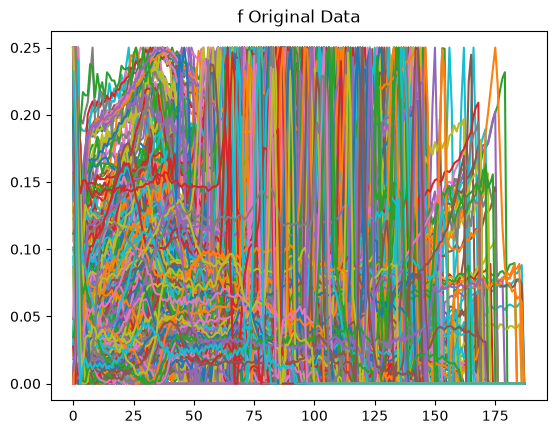

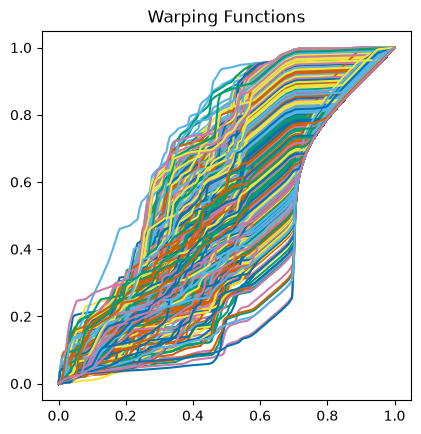

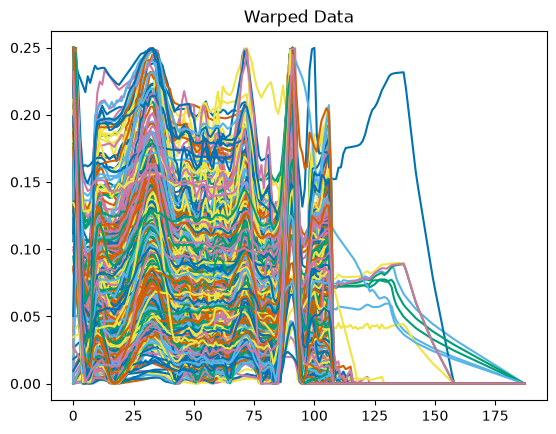

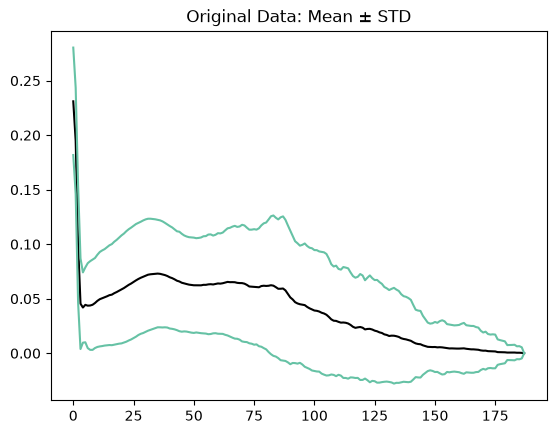

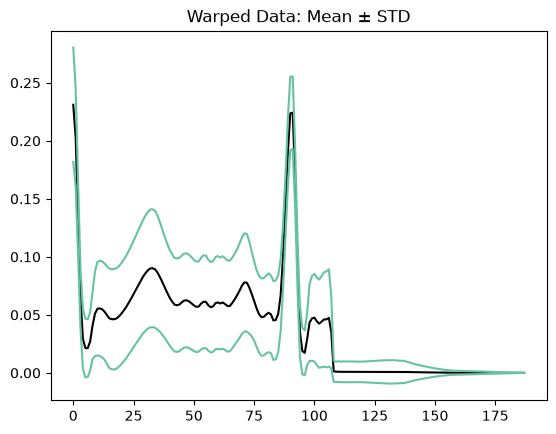

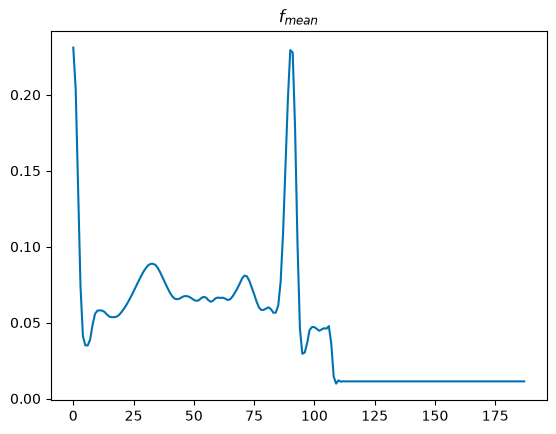

In [12]:
obj_real = fs.fdawarp(real_ecg_signal[:1000].T, np.array(list(range(len(real_ecg_signal[0])))))
obj_real.srsf_align(parallel=True, MaxItr=100)
obj_real.plot()

In [13]:
import matplotlib.pyplot as plt

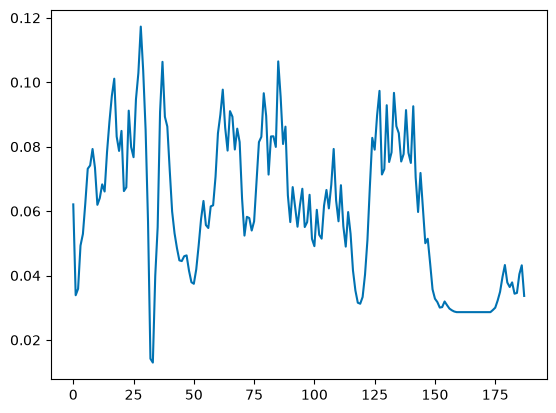

In [14]:
plt.plot(generated_ecg_signal[2])
plt.show()

Initializing...
Compute Karcher Mean of 1000 function in SRSF space with lam=0.000000
updating step: r=1
updating step: r=2
updating step: r=3
updating step: r=4
updating step: r=5
updating step: r=6
updating step: r=7
updating step: r=8
updating step: r=9
updating step: r=10
updating step: r=11
updating step: r=12
updating step: r=13
updating step: r=14
updating step: r=15
updating step: r=16
updating step: r=17
updating step: r=18
updating step: r=19
updating step: r=20
updating step: r=21
updating step: r=22
updating step: r=23
updating step: r=24
updating step: r=25
updating step: r=26
updating step: r=27
updating step: r=28
updating step: r=29
updating step: r=30
updating step: r=31
updating step: r=32
updating step: r=33
updating step: r=34
updating step: r=35
updating step: r=36
updating step: r=37
updating step: r=38
updating step: r=39
updating step: r=40
updating step: r=41
updating step: r=42
updating step: r=43
updating step: r=44
updating step: r=45
updating step: r=46
upd

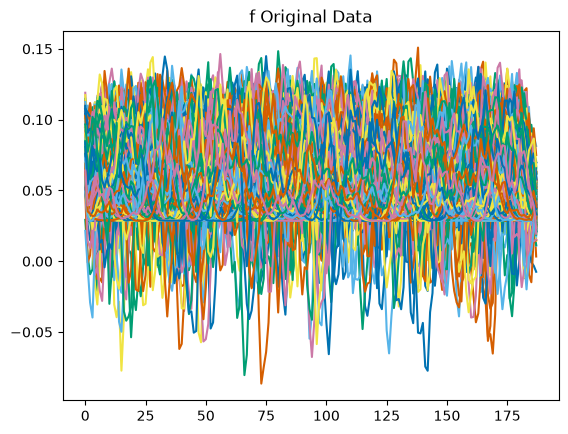

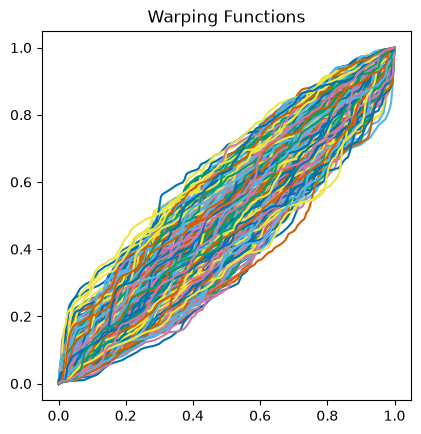

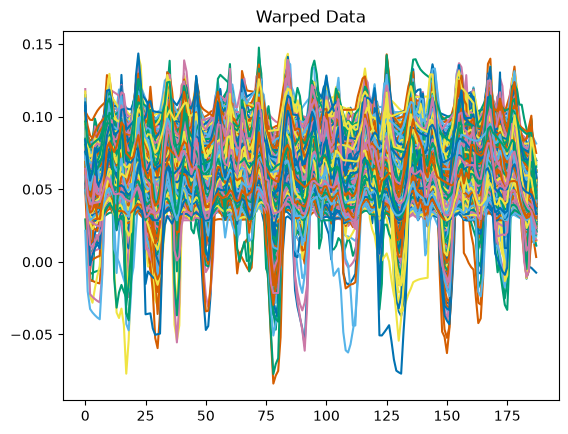

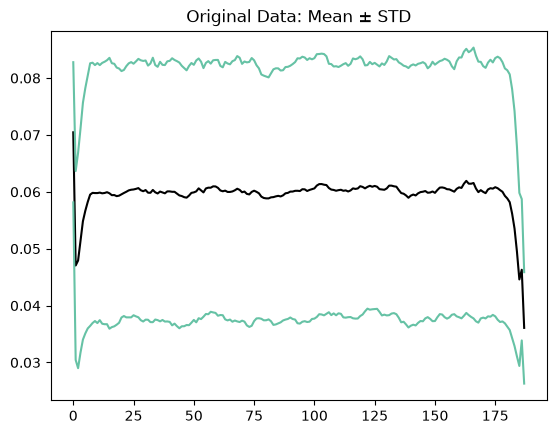

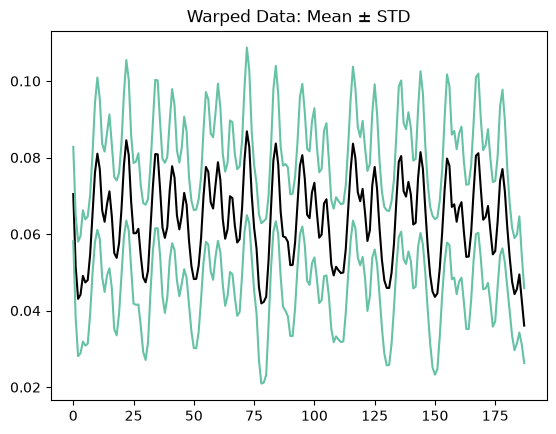

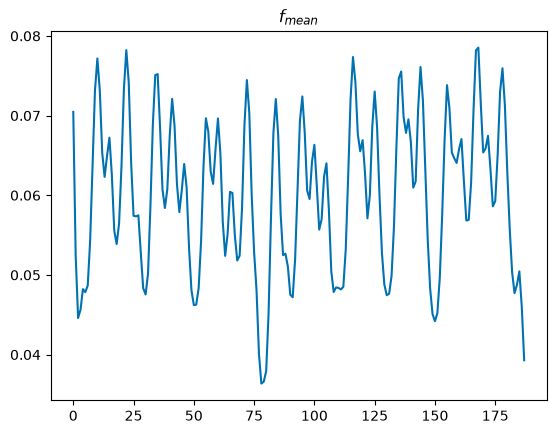

In [15]:
obj_gen = fs.fdawarp(generated_ecg_signal[:1000].T, np.array(list(range(len(generated_ecg_signal[0])))))
obj_gen.srsf_align(parallel=True, MaxItr=100)
obj_gen.plot()

## Comparison of the average real signal and the average synthetic signal
To compare the two signals, we will use dynamic time warping to mesure a distance between the two signals.

In [16]:
zeros_case = dtw.dtw(np.zeros(188,), obj_real.fmean, keep_internals=True)

In [21]:
random_case = dtw.dtw(norm.rvs(size=(188,), random_state=random_seed), obj_real.fmean, keep_internals=True)

In [17]:
alignment = dtw.dtw(obj_gen.fmean, obj_real.fmean, keep_internals=True)

In [18]:
zeros_case.distance

np.float64(10.65828213411562)

In [22]:
random_case.distance

np.float64(140.32085878985743)

In [19]:
alignment.distance

np.float64(4.761944622115249)

By looking at the distance, we can see that that the synthetic data is better than a function f(x) = 0 or a random function.

<Axes: xlabel='Index', ylabel='Query value'>

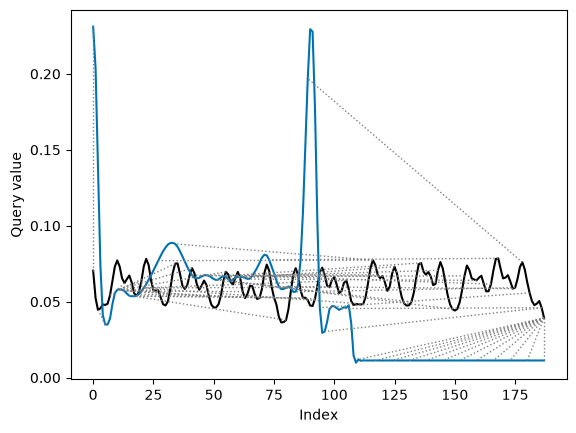

In [20]:
alignment.plot(type="twoway")

If we look at the graph, we can see that the peak of the real data is not present in the synthetic data. Therefor improvement are still needed to create nearly identical synthetic ECG.